In [1]:
# Cell 2 — Cek lokasi notebook
import os
from pathlib import Path

print("Working directory:", Path.cwd())
print("\nIsi folder:")
for item in sorted(Path.cwd().iterdir()):
    print(" ", "📁" if item.is_dir() else "📄", item.name)

Working directory: e:\Tugas 2 Klasifikasi CNN

Isi folder:
  📄 app.py
  📄 archive.zip
  📁 dataset
  📁 models
  📄 oceanic.ipynb
  📁 outputs
  📄 requirements.txt
  📄 step1_explore.py


📁 Ditemukan 23 kelas:

Nama Kelas                | Jumlah Gambar
----------------------------------------
Turtle_Tortoise           |       1903
Jelly Fish                |        845
Dolphin                   |        782
Sharks                    |        590
Sea Urchins               |        579
Whale                     |        572
Octopus                   |        562
Puffers                   |        531
Sea Rays                  |        517
Corals                    |        500
Nudibranchs               |        500
Otter                     |        500
Crabs                     |        499
Lobster                   |        499
Starfish                  |        499
Clams                     |        497
Eel                       |        497
Fish                      |        494
Shrimp                    |        488
Squid                     |        483
Penguin                   |        482
Seahorse                  |        478
Seal                      |        4

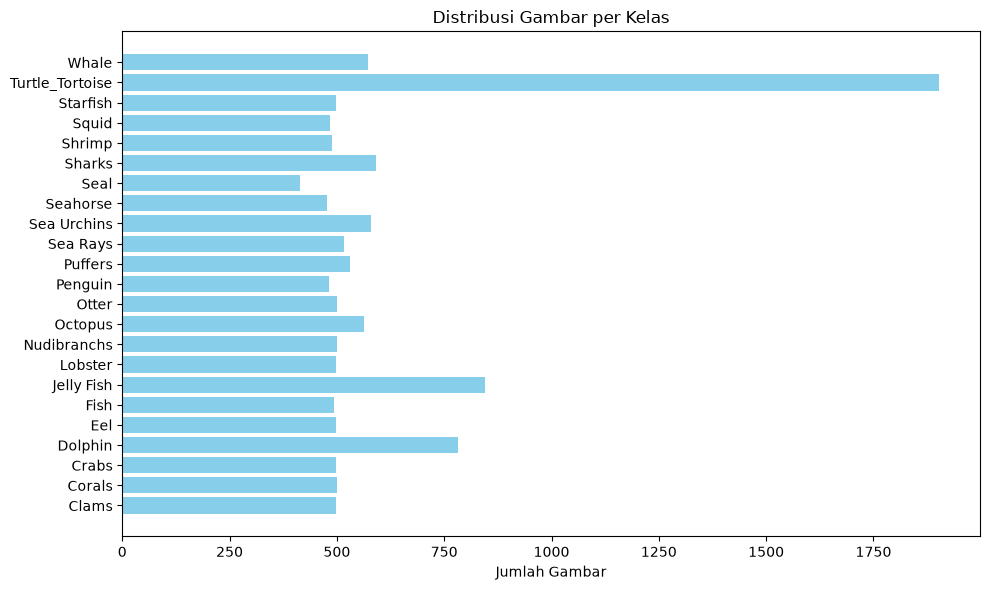

In [3]:
# Verifikasi struktur folder dataset baru
import os
from pathlib import Path
import matplotlib.pyplot as plt

# ============================================================
# GANTI PATH INI jika perlu. Asumsi: folder dataset ada di "dataset"
# ============================================================
DATASET_PATH = "dataset" 
# ============================================================

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}
root = Path(DATASET_PATH)

# 1. Daftar semua folder kelas
class_dirs = [d for d in root.iterdir() if d.is_dir()]
print(f"📁 Ditemukan {len(class_dirs)} kelas:\n")

# 2. Hitung jumlah gambar per kelas
class_counts = {}
for d in class_dirs:
    count = sum(1 for f in d.rglob("*") if f.is_file() and f.suffix.lower() in IMG_EXT)
    class_counts[d.name] = count

# 3. Tampilkan tabel distribusi
print(f"{'Nama Kelas':<25} | {'Jumlah Gambar':>10}")
print("-" * 40)
for name, count in sorted(class_counts.items(), key=lambda x: -x[1]):
    print(f"{name:<25} | {count:>10}")
print("-" * 40)
print(f"{'TOTAL':<25} | {sum(class_counts.values()):>10}")

# 4. Cek ketidakseimbangan kelas (Class Imbalance)
if class_counts:
    max_count = max(class_counts.values())
    min_count = min(class_counts.values())
    print(f"\nRasio kelas mayoritas : minoritas = {max_count/min_count:.2f} : 1")
    if max_count / min_count > 3:
        print("⚠️  Terdapat ketidakseimbangan kelas yang signifikan. Pertimbangkan class_weight saat training.")
    else:
        print("✅ Distribusi kelas cukup seimbang.")

# 5. Visualisasi (opsional, tapi bagus untuk EDA)
if class_counts:
    plt.figure(figsize=(10, 6))
    names = list(class_counts.keys())
    counts = list(class_counts.values())
    plt.barh(names, counts, color='skyblue')
    plt.xlabel('Jumlah Gambar')
    plt.title('Distribusi Gambar per Kelas')
    plt.tight_layout()
    plt.show()

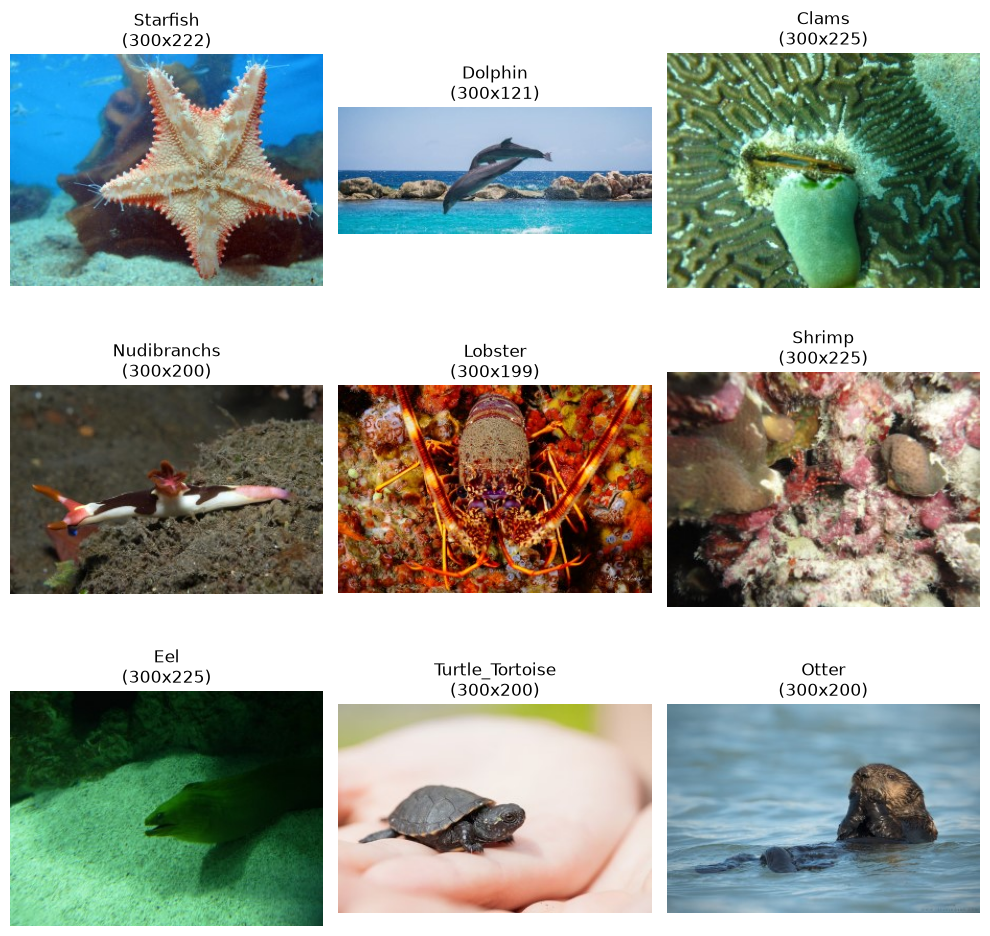

In [4]:
# Visualisasi Sampel Gambar (EDA)
import random
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

# Ambil 9 kelas secara acak
random.seed(42)
sample_classes = random.sample(list(class_counts.keys()), 9)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()

for i, cls in enumerate(sample_classes):
    class_path = root / cls
    # Ambil 1 gambar acak dari kelas tersebut
    images = list(class_path.glob("*.*"))
    img_path = random.choice(images)
    
    # Tampilkan gambar
    img = mpimg.imread(img_path)
    axes[i].imshow(img)
    axes[i].set_title(f"{cls}\n({img.shape[1]}x{img.shape[0]})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [16]:
# Siapkan Dataset (Lebih Ringan)
import tensorflow as tf

IMG_SIZE = (96, 96) # Diperkecil dari 128 agar RAM aman
BATCH_SIZE = 16     # Diperkecil dari 32
SEED = 123

print("Memuat data training (80%)...")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

print("\nMemuat data validation (20%)...")
val_dataset = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_dataset.class_names
print(f"\n✅ Ditemukan {len(class_names)} kelas.")

AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
val_dataset = val_dataset.prefetch(buffer_size=AUTOTUNE)

Memuat data training (80%)...


Found 13711 files belonging to 23 classes.
Using 10969 files for training.

Memuat data validation (20%)...
Found 13711 files belonging to 23 classes.
Using 2742 files for validation.

✅ Ditemukan 23 kelas.


In [17]:
# Data Augmentation Layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
])

In [18]:
# Cell 8 (REVISI ANTI-ERROR) — Membangun Model CNN
import tensorflow as tf
import os

os.makedirs("models", exist_ok=True)

# Kita definisikan ulang augmentasi di sini agar pasti aman
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal_and_vertical'),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
])

# Kita set langsung jumlah kelasnya (karena ada 23 kelas di dataset)
num_classes = 23 

model = tf.keras.models.Sequential([
    # 1. Input dan Augmentasi (Ukuran diubah ke 96x96)
    tf.keras.layers.Input(shape=(96, 96, 3)),
    data_augmentation, 
    
    # 2. Normalisasi
    tf.keras.layers.Rescaling(1./255),
    
    # 3. Lapisan Konvolusi 1
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    
    # 4. Lapisan Konvolusi 2
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    
    # 5. Lapisan Konvolusi 3
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    
    # 6. Flatten & Fully Connected Layer
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    
    # 7. Output Layer (23 kelas)
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

model.summary()
print("✅ Arsitektur model berhasil dibuat tanpa error!")

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_8 (Sequential)       │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │     3,277,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 23)             │         5,911 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,376,215 (12.88 MB)

 Trainable params: 3,376,215 (12.88 MB)

 Non-trainable params: 0 (0.00 B)

✅ Arsitektur model berhasil dibuat tanpa error!


In [19]:
# Pelatihan Cepat & Anti-Crash
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=1)

# Simpan model terbaik
checkpoint = ModelCheckpoint(
    'models/cnn_ocean_model.keras', 
    monitor='val_accuracy', 
    save_best_only=True, 
    verbose=1
)

EPOCHS = 10 

print("🚀 Memulai pelatihan kilat (maks 100 batch per epoch)...")
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    steps_per_epoch=100,      # <--- INI KUNCINYA (Hanya proses 100 batch per epoch)
    validation_steps=20,      # <--- Validasi hanya 20 batch
    callbacks=[early_stop, checkpoint]
)
print("✅ Pelatihan selesai!")

🚀 Memulai pelatihan kilat (maks 100 batch per epoch)...
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.1587 - loss: 2.9504
Epoch 1: val_accuracy improved from None to 0.24062, saving model to models/cnn_ocean_model.keras

Epoch 1: finished saving model to models/cnn_ocean_model.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 62s 534ms/step - accuracy: 0.1587 - loss: 2.9504 - val_accuracy: 0.2406 - val_loss: 2.7139
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 519ms/step - accuracy: 0.2138 - loss: 2.7745
Epoch 2: val_accuracy improved from 0.24062 to 0.25313, saving model to models/cnn_ocean_model.keras

Epoch 2: finished saving model to models/cnn_ocean_model.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 56s 561ms/step - accuracy: 0.2138 - loss: 2.7745 - val_accuracy: 0.2531 - val_loss: 2.7509
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 522ms/step - accuracy: 0.2106 - loss: 2.7454
Epoch 3: val_accuracy did not improve from 0.25313
100/100 ━━━━━━━━━━━━━━━━━━━━ 55s 554ms/step - accuracy: 0.2106

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 7: val_accuracy did not improve from 0.27500
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 486ms/step - accuracy: 0.2228 - loss: 2.6303 - val_accuracy: 0.2438 - val_loss: 2.6114
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.2206 - loss: 2.6248
Epoch 8: val_accuracy did not improve from 0.27500
100/100 ━━━━━━━━━━━━━━━━━━━━ 54s 537ms/step - accuracy: 0.2206 - loss: 2.6248 - val_accuracy: 0.2531 - val_loss: 2.4528
Epoch 9/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 554ms/step - accuracy: 0.2512 - loss: 2.5348
Epoch 9: val_accuracy did not improve from 0.27500
100/100 ━━━━━━━━━━━━━━━━━━━━ 58s 586ms/step - accuracy: 0.2512 - loss: 2.5348 - val_accuracy: 0.2562 - val_loss: 2.4451
Epoch 10/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 515ms/step - accuracy: 0.2425 - loss: 2.5588
Epoch 10: val_accuracy did not improve from 0.27500
100/100 ━━━━━━━━━━━━━━━━━━━━ 55s 546ms/step - accuracy: 0.2425 - loss: 2.5588 - val_accuracy: 0.2656 - val_loss: 2.3799
Restoring model weights from the end of the best 

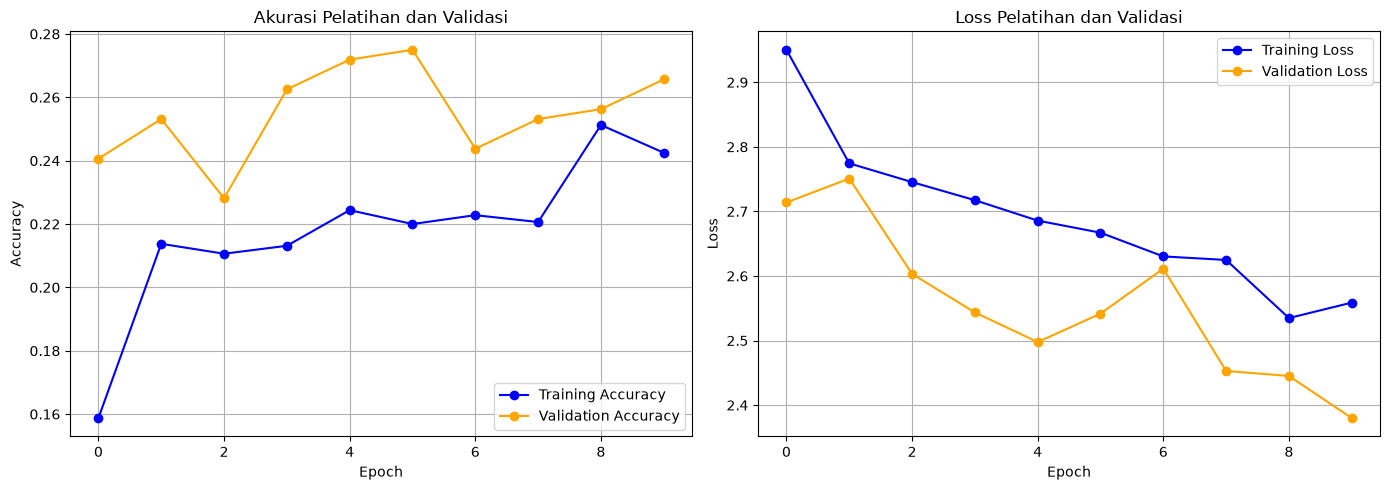

In [20]:
# Grafik Akurasi dan Loss Pelatihan
import matplotlib.pyplot as plt

# Ambil data history dari proses training (Cell 9)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

# 1. Plot Akurasi
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue', marker='o')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange', marker='o')
plt.title('Akurasi Pelatihan dan Validasi')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# 2. Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange', marker='o')
plt.title('Loss Pelatihan dan Validasi')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [21]:
# Evaluasi Metrik (Accuracy, Precision, Recall, F1)
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Memprediksi data validasi...")
# Ambil nilai asli (y_true) dan hasil prediksi (y_pred)
y_true = np.concatenate([y for x, y in val_dataset], axis=0)
y_true_classes = np.argmax(y_true, axis=1)

# Prediksi menggunakan model
y_pred_probs = model.predict(val_dataset)
y_pred_classes = np.argmax(y_pred_probs, axis=1)

# Tampilkan Classification Report
print("\n" + "="*55)
print("📋 CLASSIFICATION REPORT")
print("="*55)
print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

Memprediksi data validasi...
172/172 ━━━━━━━━━━━━━━━━━━━━ 27s 155ms/step

📋 CLASSIFICATION REPORT
                 precision    recall  f1-score   support

          Clams       0.00      0.00      0.00       102
         Corals       0.00      0.00      0.00        88
          Crabs       0.02      0.01      0.01        96
        Dolphin       0.07      0.15      0.10       176
            Eel       0.00      0.00      0.00        94
           Fish       0.00      0.00      0.00       101
     Jelly Fish       0.06      0.09      0.07       175
        Lobster       0.00      0.00      0.00       113
    Nudibranchs       0.06      0.05      0.06        94
        Octopus       0.00      0.00      0.00       107
          Otter       0.03      0.03      0.03        91
        Penguin       0.04      0.02      0.03        87
        Puffers       0.00      0.00      0.00       107
       Sea Rays       0.00      0.00      0.00       111
    Sea Urchins       0.00      0.00      0.00

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

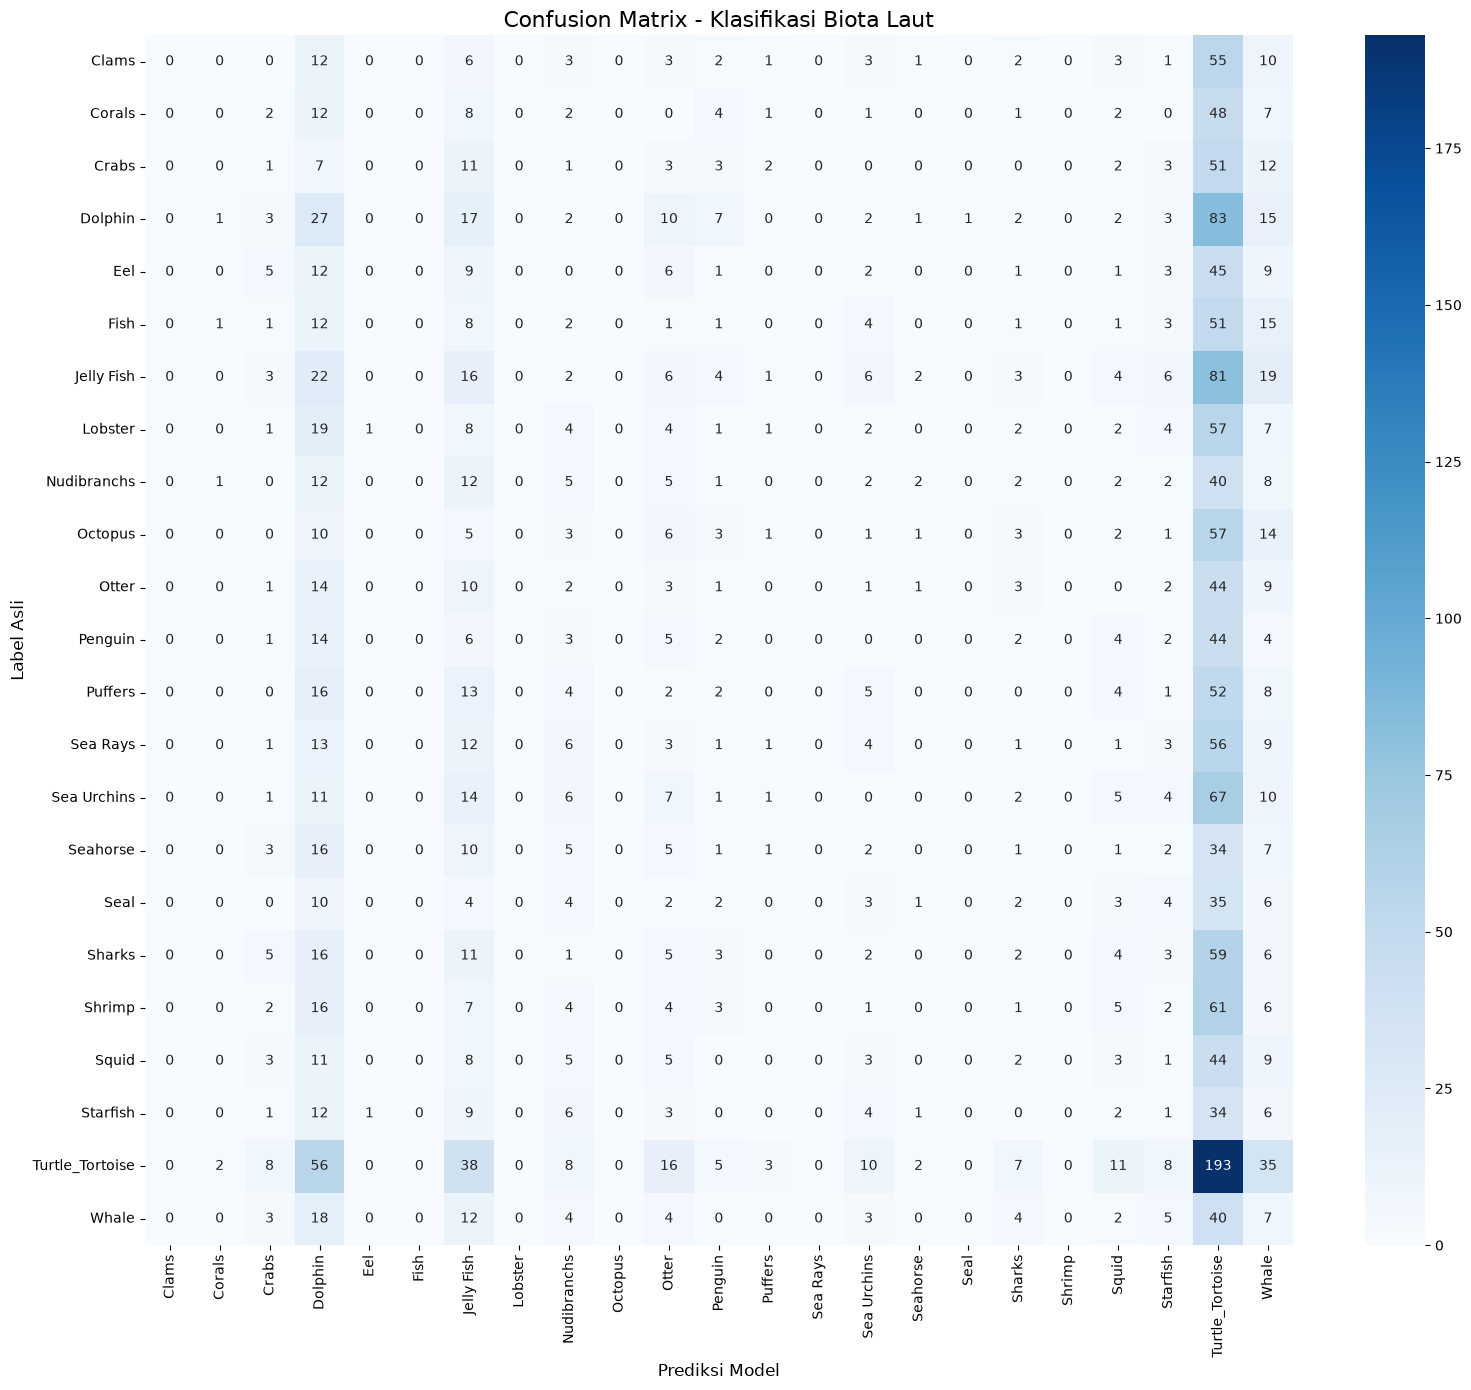

In [22]:
# Plot Confusion Matrix
plt.figure(figsize=(16, 14))

# Hitung matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Buat heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)

plt.title('Confusion Matrix - Klasifikasi Biota Laut', fontsize=16)
plt.ylabel('Label Asli', fontsize=12)
plt.xlabel('Prediksi Model', fontsize=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


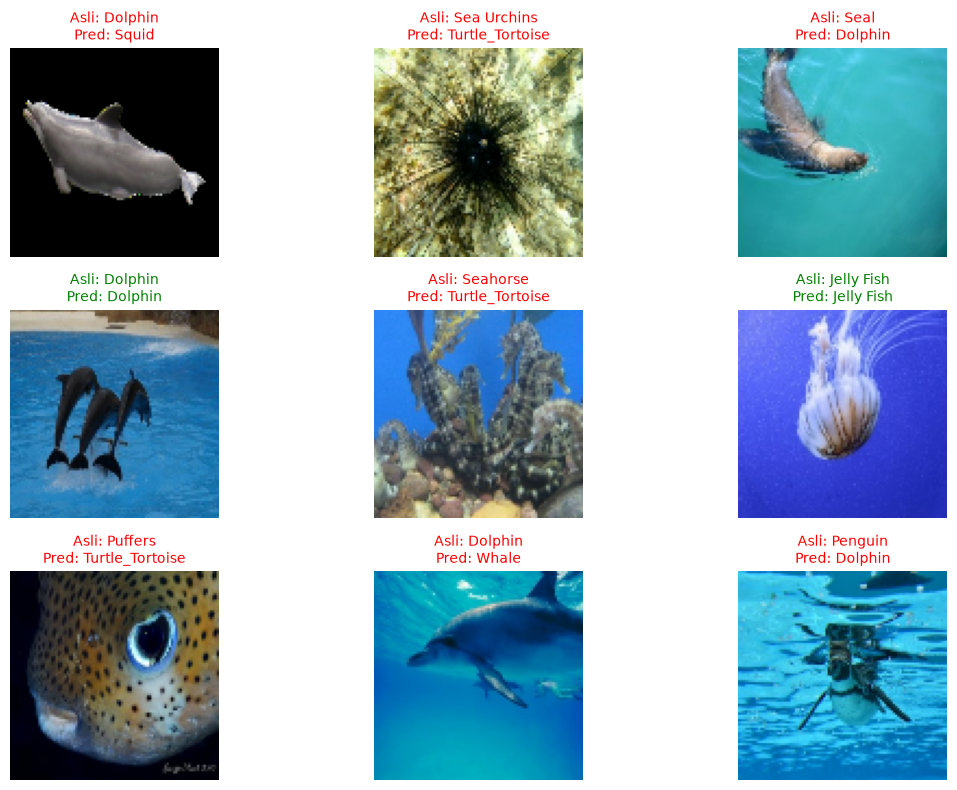

In [ ]:
# Tampilkan Sampel Gambar Uji (True vs Predicted)
import matplotlib.pyplot as plt
import numpy as np

# Ambil 1 batch dari data validasi
for images, labels in val_dataset.take(1):
    # Prediksi batch tersebut
    preds = model.predict(images)
    
    plt.figure(figsize=(12, 8))
    for i in range(9): # Tampilkan 9 gambar
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        # Label asli
        true_label = class_names[np.argmax(labels[i])]
        # Label prediksi
        pred_label = class_names[np.argmax(preds[i])]
        
        # Warna teks: Hijau jika benar, Merah jika salah
        color = 'green' if true_label == pred_label else 'red'
        
        plt.title(f"Asli: {true_label}\nPred: {pred_label}", color=color, fontsize=10)
        plt.axis("off")
    
    plt.tight_layout()
    plt.show()
    break

✅ Menggunakan layer: conv2d_14


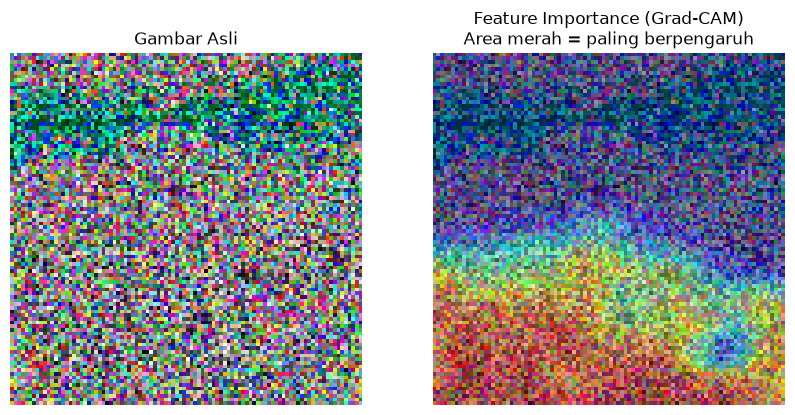

In [30]:
# Feature Importance (Grad-CAM) 
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Ambil gambar sampel dari data validasi
for images, labels in val_dataset.take(1):
    img_array = images[0].numpy()
    break

# 2. Cari layer konvolusi terakhir
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

print(f"✅ Menggunakan layer: {last_conv_layer_name}")

# 3. Fungsi Grad-CAM (Pendekatan Manual Forward Pass)
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    with tf.GradientTape() as tape:
        x = img_array
        conv_output = None
        
        # Telusuri layer satu per satu secara manual
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue
            
            # Gunakan training=False agar augmentasi (flip/rotasi) tidak aktif saat testing
            try:
                x = layer(x, training=False)
            except TypeError:
                x = layer(x) 
                
            # Simpan output jika ini adalah layer konvolusi terakhir
            if layer.name == last_conv_layer_name:
                conv_output = x
                
        preds = x
        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Hitung gradient
    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    
    # Normalisasi 0-1
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

# 4. Generate heatmap
heatmap = make_gradcam_heatmap(np.expand_dims(img_array, axis=0), model, last_conv_layer_name)

# 5. Visualisasi gabungan gambar asli & heatmap
img = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (96, 96))
heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
heatmap_colored = np.uint8(255 * heatmap_colored)

superimposed_img = cv2.addWeighted(img, 0.6, heatmap_colored, 0.4, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(img.astype('uint8'))
ax1.set_title("Gambar Asli")
ax1.axis('off')

ax2.imshow(superimposed_img)
ax2.set_title("Feature Importance (Grad-CAM)\nArea merah = paling berpengaruh")
ax2.axis('off')
plt.show()

In [34]:
import os
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import cv2

# 1. Pastikan folder outputs ada
os.makedirs("outputs", exist_ok=True)
print(f"📁 Menyimpan gambar ke folder: {os.path.abspath('outputs')}")

# ==========================================
# BAGIAN A: SIMPAN SAMPEL PREDIKSI
# ==========================================
for images, labels in val_dataset.take(1):
    preds = model.predict(images)
    
    plt.figure(figsize=(12, 8))
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        
        true_label = class_names[np.argmax(labels[i])]
        pred_label = class_names[np.argmax(preds[i])]
        color = 'green' if true_label == pred_label else 'red'
        
        plt.title(f"Asli: {true_label}\nPred: {pred_label}", color=color, fontsize=10)
        plt.axis("off")
    
    plt.tight_layout()
    plt.savefig('outputs/sample_prediksi.png', bbox_inches='tight')
    plt.close()
    print("✅ sample_prediksi.png BERHASIL disimpan")
    break

# ==========================================
# BAGIAN B: SIMPAN GRAD-CAM
# ==========================================
# Ambil gambar sampel
for images, labels in val_dataset.take(1):
    img_array = images[0].numpy()
    break

# Cari layer konvolusi
last_conv_layer_name = None
for layer in reversed(model.layers):
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_layer_name = layer.name
        break

# Fungsi Grad-CAM
def make_gradcam_heatmap(img_array, model, last_conv_layer_name):
    with tf.GradientTape() as tape:
        x = img_array
        conv_output = None
        for layer in model.layers:
            if isinstance(layer, tf.keras.layers.InputLayer):
                continue
            try:
                x = layer(x, training=False)
            except TypeError:
                x = layer(x) 
            if layer.name == last_conv_layer_name:
                conv_output = x
        preds = x
        pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]
    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

heatmap = make_gradcam_heatmap(np.expand_dims(img_array, axis=0), model, last_conv_layer_name)

img = np.uint8(255 * img_array)
heatmap_resized = cv2.resize(heatmap, (96, 96))
heatmap_colored = plt.cm.jet(heatmap_resized)[:, :, :3]
heatmap_colored = np.uint8(255 * heatmap_colored)
superimposed_img = cv2.addWeighted(img, 0.6, heatmap_colored, 0.4, 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(img.astype('uint8'))
ax1.set_title("Gambar Asli")
ax1.axis('off')

ax2.imshow(superimposed_img)
ax2.set_title("Feature Importance (Grad-CAM)\nArea merah = paling berpengaruh")
ax2.axis('off')

plt.savefig('outputs/gradcam.png', bbox_inches='tight')
plt.close()
print("✅ gradcam.png BERHASIL disimpan")

📁 Menyimpan gambar ke folder: e:\Tugas 2 Klasifikasi CNN\outputs
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
✅ sample_prediksi.png BERHASIL disimpan
✅ gradcam.png BERHASIL disimpan


In [35]:
# Membuat File CSV Data Penelitian (Metadata)
import os
import pandas as pd
from pathlib import Path

DATASET_PATH = "dataset" # Sesuaikan jika beda
IMG_EXT = {".jpg", ".jpeg", ".png"}

data_list = []

# Loop semua folder kelas dan file di dalamnya
for class_dir in Path(DATASET_PATH).iterdir():
    if class_dir.is_dir():
        for img_path in class_dir.rglob("*"):
            if img_path.is_file() and img_path.suffix.lower() in IMG_EXT:
                data_list.append({
                    "nama_file": img_path.name,
                    "kelas": class_dir.name,
                    "path_lengkap": str(img_path)
                })

# Simpan ke CSV
df_metadata = pd.DataFrame(data_list)
df_metadata.to_csv("Data_Penelitian_KlasifikasiCNN.csv", index=False)
print(f"✅ File CSV berhasil dibuat dengan {len(df_metadata)} baris data.")

✅ File CSV berhasil dibuat dengan 13711 baris data.
